# Step 5 · Temperature distribution bells

Step 4 summarised each year in a few numbers (mean, percentiles). Here we look at the **whole
distribution** of the days of each year: how many days were cold, mild or hot, and how that
changes from 1940 to today.

For each city, three charts: **minima**, **means** and **maxima**. In each one, one curve per
year (86 curves) shows how the 365 days of that year spread over the temperatures: the height
of the curve at a temperature tells how many days of the year were close to that value.

The functions are in `analysis.bells` (the curves) and `analysis.plots` (the charts).

## 1. Data

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from analysis.bells import (
    VARIABLES,
    curves_per_year,
    days_per_degree,
    decade_means,
    silverman_bandwidth,
    temperature_axis,
)
from analysis.plots import plot_bells, plot_bells_comparison, plot_decade_bells
from analysis.stats import (
    RECENT_YEARS,
    REFERENCE,
    annual_stats,
    city_summary,
    complete_years,
    read_database,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "climate.db"
LAST_YEAR = date.today().year - 1

cities, daily = read_database(DB_PATH)
daily, _ = complete_years(daily, 1940, LAST_YEAR)
annual = annual_stats(daily)
summary = cities[["name", "country", "coastal", "latitude_band"]].join(
    city_summary(annual)
)
NAMES = {
    city_id: f"{row['name']} ({row['country']})" for city_id, row in summary.iterrows()
}
print(f"{len(cities)} cities · {len(daily):,} days")

140 cities · 4,397,680 days


## 2. How a bell is built

A **histogram** counts the days that fall in each 1 °C bar. It works, but it comes out as a
staircase and depends on where the bars are cut.

The **smooth curve** (a *kernel density estimate*) puts a small **Gaussian bell** on each of the
365 days, centred on its temperature, and adds them up. The result has the same shape as the
histogram, but continuous. The width of those small bells, `h`, decides how smooth it is.

**Vertical axis, "days per °C":** each small bell has area 1, so the area under the curve is
the number of days of the year, and the height reads as the number of days in a 1 °C band
around that temperature: a peak of 20 days per °C at 26 °C means that about 20 days of the
year were between 25.5 and 26.5 °C. Like the histogram with 1 °C bars.

Below, the daily means of Madrid in 2024: the histogram, six of the small bells (one per day,
drawn 20 times taller so they can be seen) and the curve that results from adding the 366 of them.

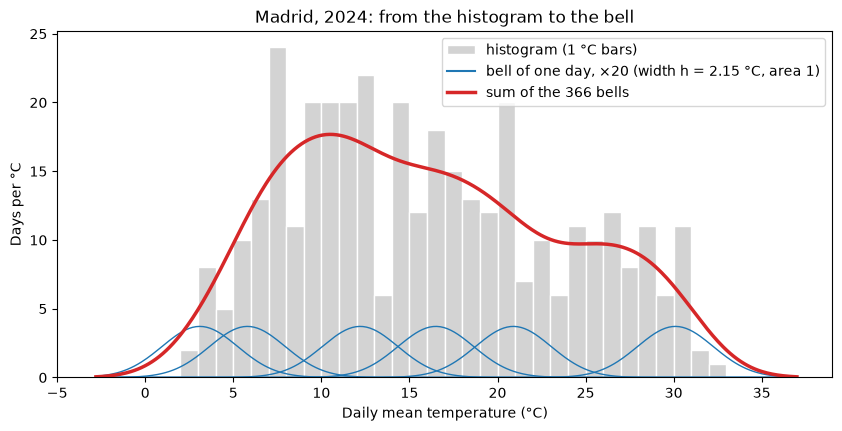

Area under the curve: 365.9 days (2024 has 366)


In [2]:
madrid_2024 = daily[(daily["city_id"] == "madrid-es") & (daily["year"] == 2024)][
    "t_mean"
]
axis = np.linspace(madrid_2024.min() - 5, madrid_2024.max() + 5, 400)
h = silverman_bandwidth(daily.loc[daily["city_id"] == "madrid-es", "t_mean"])
curve = days_per_degree(madrid_2024, axis, h)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(
    madrid_2024,
    bins=np.arange(np.floor(axis[0]), np.ceil(axis[-1]) + 1),
    color="lightgrey",
    edgecolor="white",
    label="histogram (1 °C bars)",
)
ZOOM = 20  # one day's bell is only ~0.2 days per °C high: drawn 20 times taller
for value in madrid_2024.iloc[::73]:  # six days of the year
    ax.plot(
        axis, ZOOM * days_per_degree([value], axis, h), color="tab:blue", linewidth=1
    )
ax.plot(
    [],
    [],
    color="tab:blue",
    label=f"bell of one day, ×{ZOOM} (width h = {h:.2f} °C, area 1)",
)
ax.plot(axis, curve, color="tab:red", linewidth=2.5, label="sum of the 366 bells")
ax.set_xlabel("Daily mean temperature (°C)")
ax.set_ylabel("Days per °C")
ax.set_title("Madrid, 2024: from the histogram to the bell")
ax.legend()
plt.show()

print(f"Area under the curve: {np.trapezoid(curve, axis):.1f} days (2024 has 366)")

### The width `h`: Silverman's rule

If `h` is too small, the curve copies every bump of the histogram; if it is too large, it
blurs everything into one hill. **Silverman's rule** chooses it from the spread of the data:

```
h = 0.9 × min(standard deviation, interquartile range / 1.34) × n^(−1/5)      (n = 365)
```

`h` is computed with **every day of the city** (86 years) and is **the same for all its years**:
if each year had its own `h`, the curves would change shape for that reason alone and could
not be compared. Each city and variable has its own `h`, shown in the title of each panel.

In [3]:
widths = pd.DataFrame(
    {
        name: {
            NAMES[city_id]: silverman_bandwidth(
                daily.loc[daily["city_id"] == city_id, variable]
            )
            for city_id in ["madrid-es", "manaus-br", "yakutsk-ru"]
        }
        for variable, name in VARIABLES
    }
)
widths.round(2)

,Daily minima,Daily means,Daily maxima
Madrid (Spain),1.86,2.15,2.43
Manaus (Brazil),0.21,0.31,0.55
Yakutsk (Russia),5.85,6.02,6.22


## 3. The bell of every year

`plot_bells`: **minima**, **means** and **maxima** of a city, one curve per year.

**How to read it:**
- Colour = year, from **blue (1940)** to **red (2025)**. The thin curves are single years; the
  **thick** ones, the mean of each decade.
- If the city warms, the red curves sit **to the right** of the blue ones.
- The three panels share the temperature axis, so the distance between minima and maxima can be
  seen too.
- **It is not always a bell:** where the seasons are very marked there are **two humps**, winter
  and summer. In the tropics there is one narrow bell. It is the real shape of each climate.

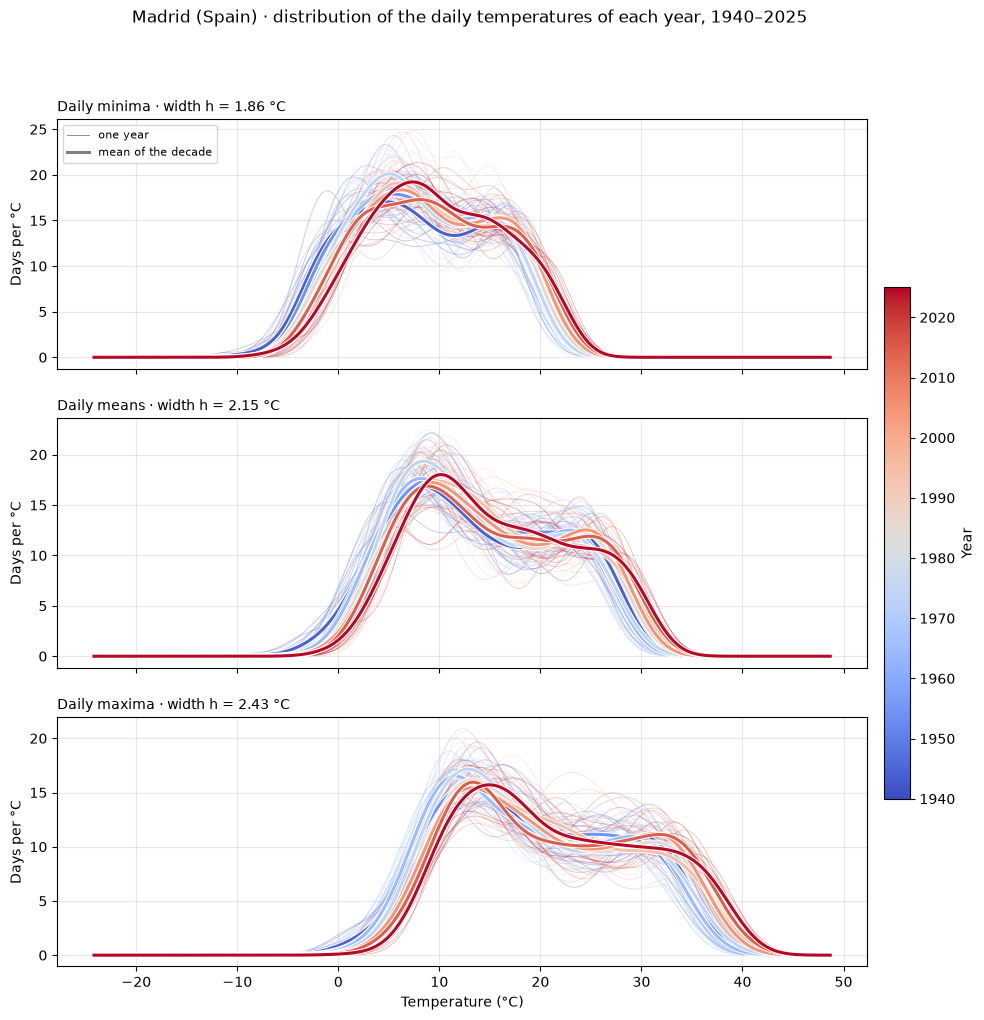

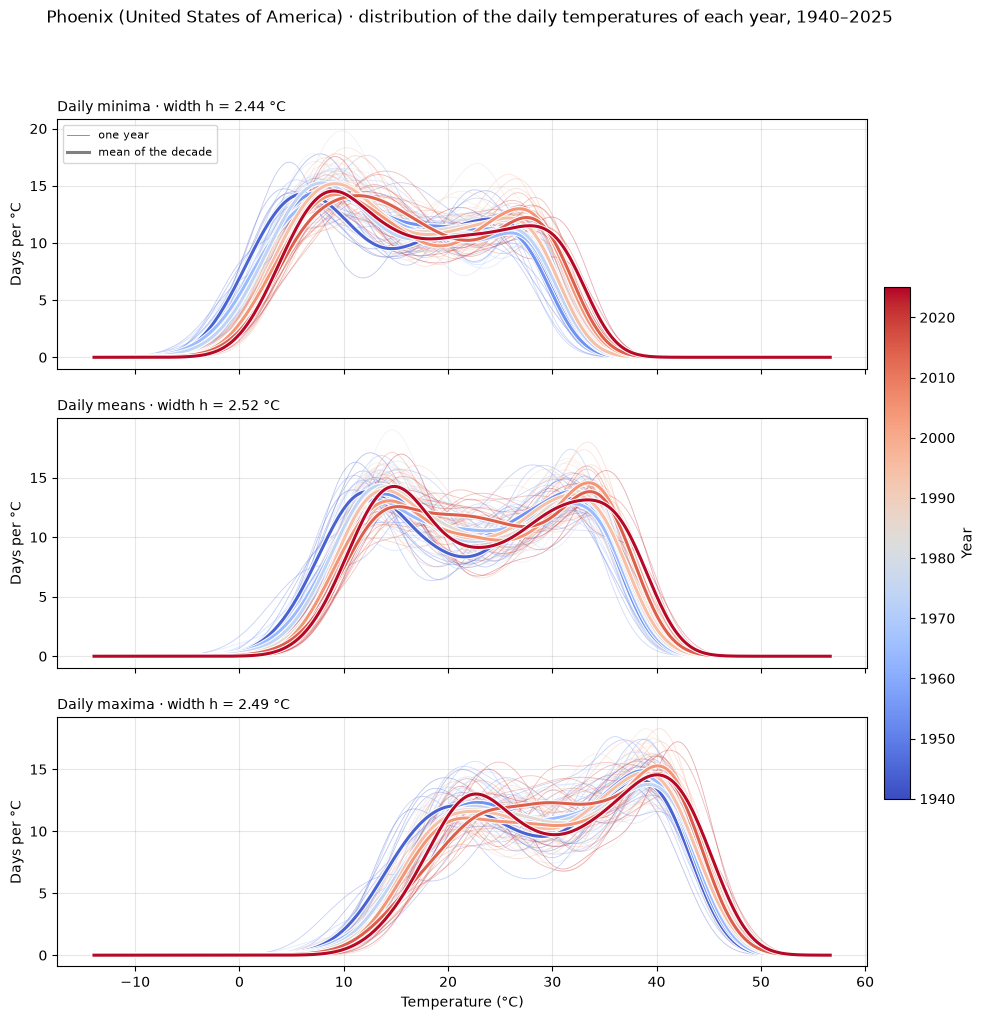

In [4]:
for city_id in ["madrid-es", "phoenix-us"]:
    plot_bells(daily, city_id, title=NAMES[city_id])
    plt.show()

## 4. Only the decades

The 86 curves carry a lot of information but are hard to read. `plot_decade_bells` draws only
**the mean of each decade** (9 curves per variable): the thick curves of section 3, without the
thin ones. The last decade is incomplete (2020–2025, 6 years) and its label says so.

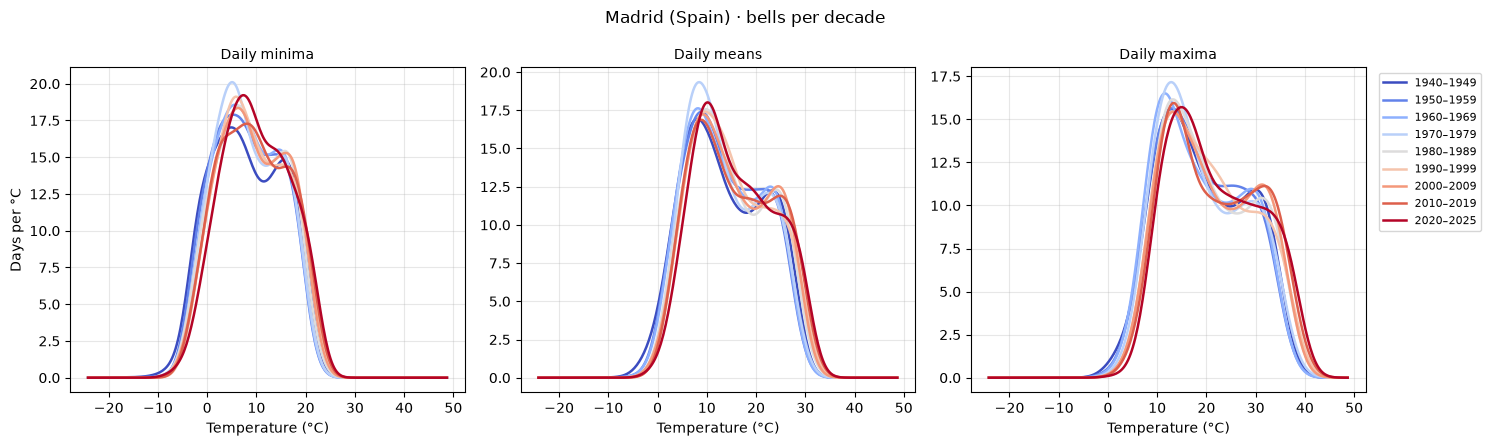

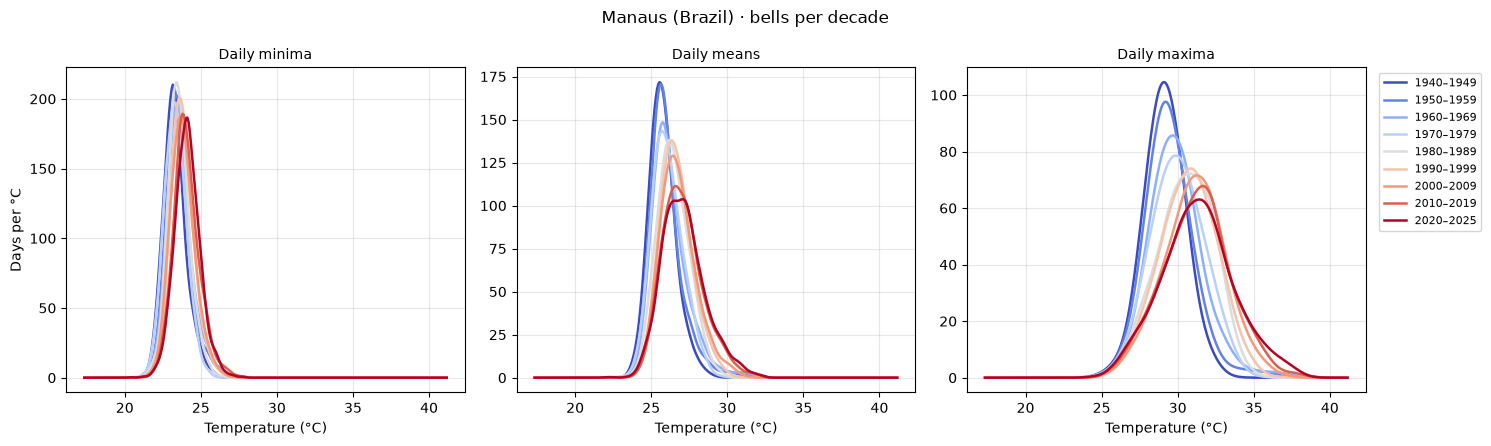

In [5]:
for city_id in ["madrid-es", "manaus-br"]:
    plot_decade_bells(daily, city_id, title=NAMES[city_id])
    plt.show()

## 5. Several cities

`plot_bells_comparison`: one panel per city, decade bells of one variable. Each panel has **its
own temperature axis**, because climates are very different: compare how the curves **move**
from blue to red, not where they are.

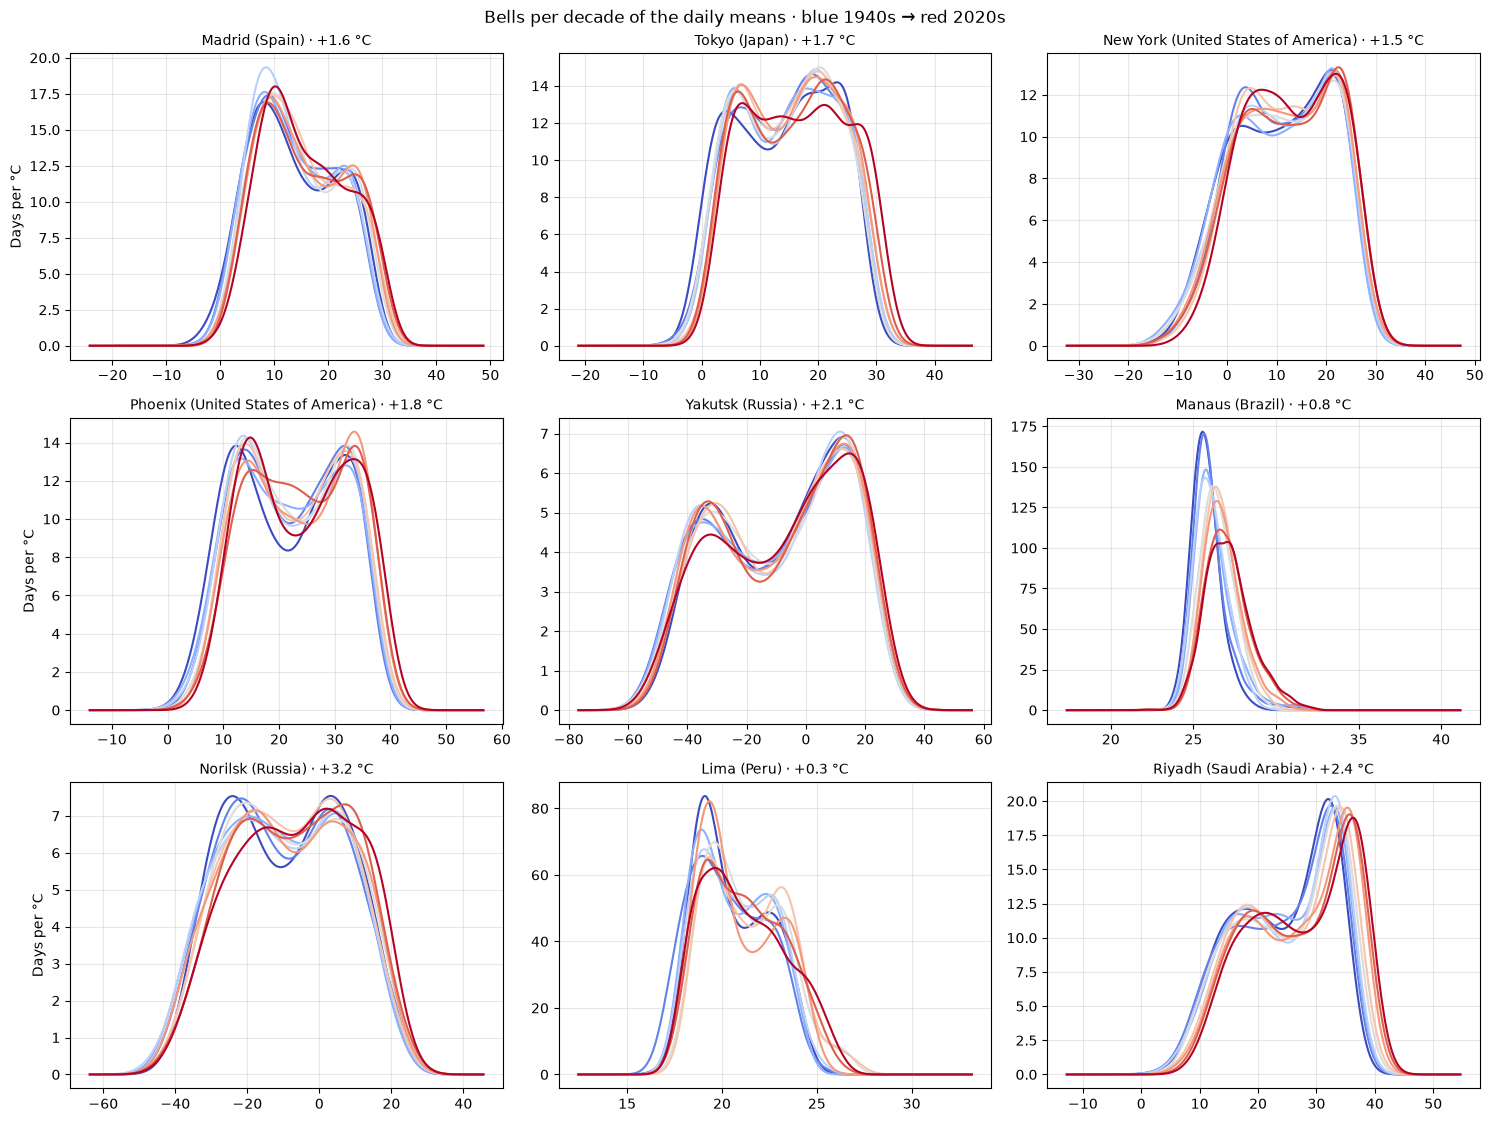

In [6]:
CITIES = [
    "madrid-es",
    "tokyo-jp",
    "new-york-us",
    "phoenix-us",
    "yakutsk-ru",
    "manaus-br",
    "norilsk-ru",
    "lima-pe",
    "riyadh-sa",
]
titles = {c: f"{NAMES[c]} · {summary.loc[c, 'difference']:+.1f} °C" for c in CITIES}
plot_bells_comparison(daily, CITIES, titles=titles, variable="t_mean")
plt.show()

## 6. Does the whole distribution move, or only one side?

The bells show it by eye; the percentiles of step 4 measure it. For each city, how much the
**5th percentile** (the cold days of the year) and the **95th percentile** (the hot days) of the
daily mean rose between 1961–1990 and the last 10 years.

Median rise, last 10 years vs 1961–1990:
p05    1.05
p50    0.99
p95    1.11
Cities where the cold days (p05) rise more than the hot ones (p95): 69 of 140


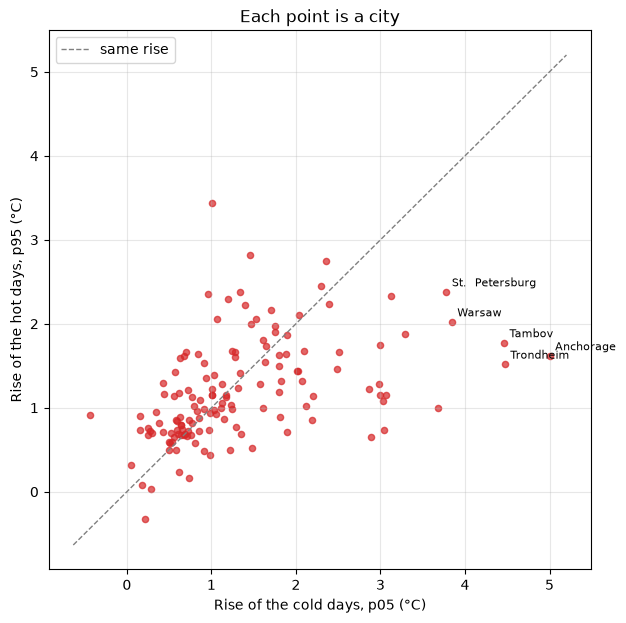

,name,latitude_band,p05,p50,p95
city_id,,,,,
anchorage-us,Anchorage,subpolar_north,5.00,1.74,1.62
trondheim-no,Trondheim,subpolar_north,4.47,1.33,1.52
tambov-ru,Tambov,temperate_north,4.46,2.19,1.77
warsaw-pl,Warsaw,temperate_north,3.84,1.22,2.02
st-petersburg-ru,St. Petersburg,temperate_north,3.78,1.44,2.38
reykjavik-is,Reykjavík,subpolar_north,3.68,1.16,1.00
murmansk-ru,Murmansk,polar_north,3.29,1.29,1.88
norilsk-ru,Norilsk,polar_north,3.13,3.86,2.34


In [7]:
years = annual.index.get_level_values("year")
recent = (
    annual[years > LAST_YEAR - RECENT_YEARS]
    .groupby("city_id")[["p05", "p50", "p95"]]
    .mean()
)
reference = (
    annual[(years >= REFERENCE[0]) & (years <= REFERENCE[1])]
    .groupby("city_id")[["p05", "p50", "p95"]]
    .mean()
)
shift = (recent - reference).join(summary[["name", "latitude_band"]])

print("Median rise, last 10 years vs 1961–1990:")
print(shift[["p05", "p50", "p95"]].median().round(2).to_string())
print(
    f"Cities where the cold days (p05) rise more than the hot ones (p95): "
    f"{(shift['p05'] > shift['p95']).sum()} of {len(shift)}"
)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(shift["p05"], shift["p95"], s=20, color="tab:red", alpha=0.7)
limit = [min(shift[["p05", "p95"]].min()) - 0.2, max(shift[["p05", "p95"]].max()) + 0.2]
ax.plot(limit, limit, color="grey", linestyle="--", linewidth=1, label="same rise")
for city_id in shift["p05"].nlargest(5).index:
    ax.annotate(
        shift.loc[city_id, "name"],
        (shift.loc[city_id, "p05"], shift.loc[city_id, "p95"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
    )
ax.set_xlabel("Rise of the cold days, p05 (°C)")
ax.set_ylabel("Rise of the hot days, p95 (°C)")
ax.set_title("Each point is a city")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

shift.sort_values("p05", ascending=False)[
    ["name", "latitude_band", "p05", "p50", "p95"]
].round(2).head(8)

## 7. Check: the area of every bell

For every city, variable and decade, the area under the mean curve must be about the number of
days in a year (365.25 on average). This checks `temperature_axis` (no curve is cut at the
edges) and `days_per_degree` on the 140 cities. A coarse axis of 120 points is enough here.

In [8]:
areas = []
for city_id, city_daily in daily.groupby("city_id"):
    axis = temperature_axis(city_daily, points=120)
    for variable, _ in VARIABLES:
        for curve in decade_means(
            curves_per_year(city_daily, variable, axis)[1]
        ).values():
            areas.append(np.trapezoid(curve, axis))
areas = np.array(areas)
print(f"{len(areas)} curves (140 cities × 3 variables × 9 decades)")
print(f"Area: min {areas.min():.1f}, max {areas.max():.1f} days")
assert ((areas > 364) & (areas < 367)).all()
print("OK: every curve holds a year of days")

3780 curves (140 cities × 3 variables × 9 decades)
Area: min 365.2, max 365.3 days
OK: every curve holds a year of days


## Conclusions

**How the bells are built**
- Each day adds a small Gaussian bell of area 1, so the area under a year's curve is its number
  of days and the vertical axis reads in **days per °C**, like a histogram with 1 °C bars.
- The width `h` (Silverman's rule) is computed once per city and variable, so the years are
  comparable. It goes from 0.21 °C (Manaus' minima: a very regular climate) to about 6 °C
  (Yakutsk: from −40 °C in winter to +20 °C in summer).
- **Check:** the 3,780 decade curves (140 cities × 3 variables × 9 decades) hold between 365.2
  and 365.3 days. Running this check showed that the original 5 % margin of the temperature
  axis cut the tails of the hottest days in a few cities (Riyadh and Naha lost ~1.5 days in the
  2020s); the axis now leaves at least 3 bell widths beyond the extreme days.

**What the bells show**
- **The whole distribution moves to the right:** red curves (recent decades) sit to the right
  of the blue ones in almost every city. The median rise between 1961–1990 and the last 10 years
  is about the same for cold days (p05 +1.05 °C), typical days (p50 +0.99) and hot days
  (p95 +1.11).
- **The shape depends on the climate:** two humps (winter and summer) where seasons are marked
  (Madrid, Tokyo, Phoenix, Yakutsk, Norilsk), and one narrow, tall bell in the tropics (Manaus,
  with peaks of over 150 days per °C).
- **In cold climates the cold tail warms the most:** in 69 of the 140 cities the cold days rise
  more than the hot ones, and the biggest rises are in the north: the 5th percentile goes up
  +5.0 °C in Anchorage, +4.5 in Trondheim and Tambov, +3.8 in Warsaw and St. Petersburg. The
  days of extreme cold are disappearing.
- **In the tropics the bell also gets wider:** in Manaus the peak drops from ~170 to ~100 days
  per °C while it moves ~1 °C to the right: the days are not only warmer, but less regular.
- **Little change where the ocean rules:** in Lima the decades overlap much more (+0.3 °C).

**Precautions**
- The same as in step 4: fewer observations before 1950 and possible model jumps before ~1960
  in some cities; ERA5 cells of ~25 km, not weather stations.